In [4]:
import pandas as pd
import pandas as pd

df = pd.read_csv(
    r"S:\DA  notes\E_Comm_dataset.csv"
)

df.head()

,user_ID,Name,Age,Gender,City,Education_Level,Monthly_Income,Marrige_Status,Date_of_order,Product_order_count,Order_Amount_INR,Wallet_Balance_INR,Total_Order_INR
0,1.0,NaN,NaN,Female,NaN,Graduate,52860.0,Single,10-03-2023,4.0,NaN,21822.0,23134.0
1,2.0,NaN,26.0,Male,Delhi,Graduate,NaN,Single,14-04-2024,1.0,20495.0,17493.0,19110.0
2,3.0,Anjali Agarwal,27.0,Female,Delhi,10th,25753.0,Single,NaN,3.0,6057.0,13325.0,14916.0
3,4.0,NaN,20.0,Female,NaN,Graduate,NaN,Divorced,27-02-2024,4.0,3171.0,11955.0,11995.0
4,5.0,Arjun Jain,28.0,Male,Delhi,Graduate,35921.0,NaN,24-05-2024,1.0,6695.0,3063.0,6242.0


In [5]:
# indentify the null values
df.isnull().sum()

user_ID                  3000
Name                   195000
Age                     45000
Gender                  15000
City                    37500
Education_Level         25000
Monthly_Income          30000
Marrige_Status          20000
Date_of_order           10000
Product_order_count     22500
Order_Amount_INR        25000
Wallet_Balance_INR      30000
Total_Order_INR          3750
dtype: int64

In [6]:
df.isna().sum()

user_ID                  3000
Name                   195000
Age                     45000
Gender                  15000
City                    37500
Education_Level         25000
Monthly_Income          30000
Marrige_Status          20000
Date_of_order           10000
Product_order_count     22500
Order_Amount_INR        25000
Wallet_Balance_INR      30000
Total_Order_INR          3750
dtype: int64

#### Approach 1: Delete Rows
###### Use when only a small number of rows contain missing values.

In [7]:
# EDA-5.1: Calculating the Percentage of Null Values
# Definition: Calculates the percentage of missing values in each column.
# Importance: Helps decide whether to delete rows or use another method
# to handle missing values.

for col in df.columns:
    print((df[col].isnull().sum() / len(df)) * 100)

1.2
78.0
18.0
6.0
15.0
10.0
12.0
8.0
4.0
9.0
10.0
12.0
1.5


In [8]:
# EDA-5.2: Deleting Rows with Null Values in Specific Columns
# Definition: dropna() removes rows containing missing values in the specified columns.
# Importance: Keeps records where both user_ID and Total_Order_INR are available.
# Note: In real projects, discuss data deletion with the customer or team first.

df.dropna(subset=['user_ID', 'Total_Order_INR'], inplace=True)

# Checking Remaining Null Values in Each Column
# Definition: Counts the missing values remaining after deletion.
df.isnull().sum()

user_ID                     0
Name                   189763
Age                     43786
Gender                  14617
City                    36498
Education_Level         24359
Monthly_Income          29171
Marrige_Status          19483
Date_of_order            9744
Product_order_count     21930
Order_Amount_INR        24305
Wallet_Balance_INR      29191
Total_Order_INR             0
dtype: int64

In [9]:
# Checking the Shape of the Dataset
# Definition: shape returns the number of rows and columns.
# Importance: Helps check the dataset size after data cleaning.
# Output format: (number of rows, number of columns)

df.shape

(243297, 13)

#### Approach 2: Delete Columns
##### Use when a column contains too many missing values

In [10]:
# EDA-5.3: Deleting Columns with More Than 70% Null Values
# Definition: Removes columns where more than 70% of the values are missing.
# Importance: Helps remove columns with too little useful information.
# Note: Before deleting a column, discuss it with the customer or team.

In [11]:
# EDA-5.4: Deleting a Column and Checking Null Values
# Definition: drop() removes the specified column from the DataFrame.
# Importance: Removes an unnecessary column after confirming with the customer.

df.drop(columns=['Name'], inplace=True)

# Checking Remaining Null Values
# Definition: isna() identifies missing values, and sum() counts them.
# Importance: Checks how many null values remain in each column.

df.isna().sum()

user_ID                    0
Age                    43786
Gender                 14617
City                   36498
Education_Level        24359
Monthly_Income         29171
Marrige_Status         19483
Date_of_order           9744
Product_order_count    21930
Order_Amount_INR       24305
Wallet_Balance_INR     29191
Total_Order_INR            0
dtype: int64

#### Approach 3: Fill with a Constant Value
###### Example: Fill missing city values with 'Other'.

In [12]:
# EDA-5.5: Filling Null Values with a Constant
# Definition: fillna() replaces missing values with a specified value.
# Importance: Keeps the records instead of deleting them.
# Here, missing values in City are replaced with "Other".

df.City = df.City.fillna("Other")

# Checking Remaining Null Values
# Definition: Counts missing values in each column.
# Importance: Verifies whether null values remain after filling City.

df.isna().sum()

user_ID                    0
Age                    43786
Gender                 14617
City                       0
Education_Level        24359
Monthly_Income         29171
Marrige_Status         19483
Date_of_order           9744
Product_order_count    21930
Order_Amount_INR       24305
Wallet_Balance_INR     29191
Total_Order_INR            0
dtype: int64

In [13]:
df.shape

(243297, 12)

In [14]:
df.Education_Level.unique()

array(['Graduate', '10th', '12th', 'Postgrad', nan], dtype=object)

In [15]:
df.Education_Level = df.Education_Level.fillna("Unknown")
df.isna().sum()

user_ID                    0
Age                    43786
Gender                 14617
City                       0
Education_Level            0
Monthly_Income         29171
Marrige_Status         19483
Date_of_order           9744
Product_order_count    21930
Order_Amount_INR       24305
Wallet_Balance_INR     29191
Total_Order_INR            0
dtype: int64

###### Approach 4: Fill with Mean, Median, or Mode

In [16]:
# Interview Question: When Should We Use Mean, Median, or Mode to Replace Null Values?

# 1. Mean
# Definition: Mean is the average of all values.
# When to use: Numerical data without significant outliers.
# Example: Age, height, or salary when the data is fairly balanced.

# 2. Median
# Definition: Median is the middle value after sorting the data.
# When to use: Numerical data with outliers or skewed distributions.
# Example: Salary, house prices, or income.

# 3. Mode
# Definition: Mode is the most frequently occurring value.
# When to use: Categorical data or numerical data with repeated values.
# Example: City, occupation, education, or the most common age.

In [17]:
# Mean: When to Replace Null Values with Mean
# 1. Data must be numerical.
# 2. Data should not have significant outliers.
# 3. Data should be approximately symmetrical or normally distributed.
# 4. Mean is affected by extreme values.
# 5. Example: Replacing missing height values with the average height.

<Axes: xlabel='Age'>

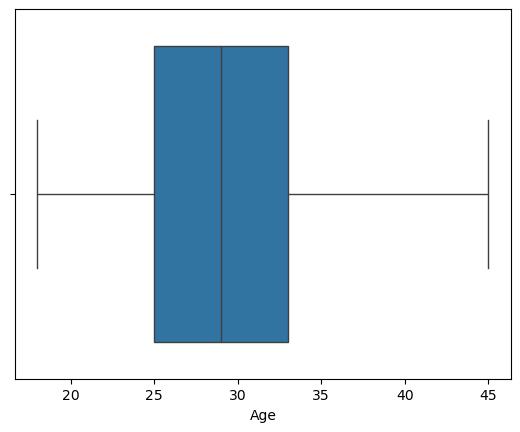

In [18]:
# EDA-5.6: Detecting Outliers Using a Boxplot
# Definition: A boxplot displays the distribution of numerical data and helps identify outliers.
# Importance: Helps decide whether mean or median is more suitable for filling null values.

import seaborn as sns
sns.boxplot(x='Age', data=df)

In [19]:
# Task-1: Finding the Mean of the Age Column
# Definition: mean() calculates the average of all non-null values in Age.
# Importance: Helps find the average age and can be used to fill missing values
# when mean imputation is appropriate.

mean_value = df.Age.mean()
mean_value

np.float64(29.030770233220224)

In [20]:
# Task-2: Filling Null Values in the Age Column with the Mean
# Definition: fillna() replaces missing Age values with the calculated mean.
# Importance: Keeps the records instead of deleting rows with missing ages.

df.Age = df.Age.fillna(mean_value)

# Checking Remaining Null Values
# Definition: Counts the missing values in each column.
# Importance: Verifies whether the missing Age values have been filled.

df.isna().sum()

user_ID                    0
Age                        0
Gender                 14617
City                       0
Education_Level            0
Monthly_Income         29171
Marrige_Status         19483
Date_of_order           9744
Product_order_count    21930
Order_Amount_INR       24305
Wallet_Balance_INR     29191
Total_Order_INR            0
dtype: int64

In [21]:
# Median: When to Replace Null Values with Median
# 1. Use median when the data contains outliers.
# 2. Use median when the data is skewed.
# 3. Median is less affected by extreme values than mean.
# 4. It is suitable for numerical data.
# 5. Example: Salary, house prices, and income.

In [22]:
# Task: Finding the Median of Monthly_Income
# Definition: median() returns the middle value of the non-null values.
# Importance: Median is useful when income data contains outliers or is skewed.

median_value = df.Monthly_Income.median()
median_value

55192.0

In [23]:
# Task: Filling Null Values in Monthly_Income with the Median
# Definition: fillna() replaces missing income values with the calculated median.
# Importance: Keeps records and reduces the influence of outliers on imputation.

df.Monthly_Income = df.Monthly_Income.fillna(median_value)

# Checking Remaining Null Values
# Definition: isnull() identifies missing values, and sum() counts them.
# Importance: Verifies whether missing values remain in each column.

df.isnull().sum()

user_ID                    0
Age                        0
Gender                 14617
City                       0
Education_Level            0
Monthly_Income             0
Marrige_Status         19483
Date_of_order           9744
Product_order_count    21930
Order_Amount_INR       24305
Wallet_Balance_INR     29191
Total_Order_INR            0
dtype: int64